# Step 1 — Data preprocessing and exploratory analysis

Turns the raw JDsearch text files into typed tables, removes the label leak in the raw slate order, splits users, and runs the exploratory analysis that drives every later design decision (in particular the history retention windows raised in the interim feedback).

### Setup (run first)

**On Google Colab:** *Runtime → Change runtime type → GPU* (T4 is enough; A100/L4 is faster). Put the two raw JDsearch
files in `MyDrive/bt4222/raw/` (`user_behavior_data.txt`, `product_meta_data.txt`). The cell mounts Drive, clones the
repository, installs the requirements and writes every output to `MyDrive/bt4222/outputs/`, so results persist between
sessions and the notebooks can be run one after another (or on different days).

**Locally:** run the notebook from the repository with the virtual environment active; data is read from `data/raw/`
and outputs go to `outputs/`.

`CONFIG = "configs/smoke.yaml"` runs everything on a 2,000-user sample with tiny models (minutes, CPU) to check the code;
`configs/default.yaml` is the real run. Every stage skips work whose outputs already exist; pass `"--force"` to redo one.

In [1]:
import os, subprocess, sys
from pathlib import Path

CONFIG = "configs/default.yaml"          # "configs/smoke.yaml" for a quick check
REPO_URL = "https://github.com/clarequek/bt4222-two-tower-recsys.git"
DRIVE_DIR = "/content/drive/MyDrive/bt4222"   # Colab: raw/ (input) and outputs/ (written by the pipeline)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/bt4222-two-tower-recsys")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(ROOT)], check=True)
    else:
        subprocess.run(["git", "-C", str(ROOT), "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

from jds.notebook import Runner, banner
run = Runner(CONFIG, drive_dir=DRIVE_DIR if IN_COLAB else None)

config configs/default.yaml | scope full | raw data /home/ubuntu/bt4222-two-tower-recsys/data/raw | outputs /home/ubuntu/bt4222-two-tower-recsys/outputs/full


## 1.1 Preprocessing (`scripts/00_prepare.py`, `src/jds/prepare.py`)

What it does and why:
* **Parses** the user file (one row = one search session: test query, displayed slate with labels, history) and the
  4.8 GB product file (streamed, kept only for items that appear in the logs).
* **History timestamps.** `history_time_list` holds *gaps in seconds* between consecutive events, the last one being the
  gap to the test query. Summing from the end gives each event's **age in days before the test query** (`age_days`),
  the quantity the interim feedback asked us to trace.
* **Leakage control.** In the raw file every slate is sorted by label (positives first in 100% of slates), so the
  original position would give the answer away. Every slate is shuffled with a fixed seed; the original position is
  kept only for auditing and is never a feature.
* **Split by user** 80 / 10 / 10 into train / validation / test (only users with at least one positive are evaluated);
  training users get one of 5 folds for cross-fitting (out-of-fold CTR features and tower scores, see steps 2 and 5).

In [2]:
run.stage("00_prepare.py")

$ /home/ubuntu/bt4222-two-tower-recsys/.venv/bin/python -u scripts/00_prepare.py --config configs/default.yaml


06:01:46 prepare | full data already prepared in /home/ubuntu/bt4222-two-tower-recsys/outputs/full/data (use --force to rebuild)


In [3]:
run.json("prepare_stats.json")

{'users': 173831,
 'users_with_pos': 171728,
 'impressions': 15510012,
 'history_events': 26667260,
 'distinct_queries': 1740829,
 'items_with_metadata': 11588589,
 'split_sizes': {'test': 17174, 'train': 139485, 'val': 17172},
 'positives_first_in_raw_order': 1.0,
 'integrity': {'history lists have equal length': True,
  'time list is one longer (includes the test query)': True,
  'candidate ids and labels have equal length': True}}

## 1.2 Exploratory analysis (`scripts/01_eda.py`, `src/jds/eda.py`)

**The history is three logs with different retention windows.** Counted back from the test query, clicks are only kept
for 7 days, carts and follows for 90 days, orders for 365 days. That is why orders and carts outnumber clicks overall:
beyond 7 days a missing click means *not recorded*, not *did not click*. Inside the 7-day window the funnel looks like a
normal e-commerce funnel.

In [4]:
run.stage("01_eda.py")

$ /home/ubuntu/bt4222-two-tower-recsys/.venv/bin/python -u scripts/01_eda.py --config configs/default.yaml


06:01:55 eda | funnel by elapsed days:


shape: (9, 10)


┌─────────┬─────────┬─────────┬────────┬───┬────────┬───────────────┬───────────────┬──────────────┐


│ bucket  ┆ events  ┆ click   ┆ follow ┆ … ┆ users  ┆ clicks_per_ca ┆ carts_per_ord ┆ cum_share_of │


...

│ 2    ┆ 24579    ┆ 39.443935 ┆ 87.698425  ┆ 89.359146  ┆ 89.986595  ┆ FLW       │


│ 3    ┆ 11526504 ┆ 38.373692 ┆ 88.306122  ┆ 89.458969  ┆ 635.289856 ┆ CART      │


│ 4    ┆ 6817283  ┆ 154.0802  ┆ 359.576172 ┆ 363.995087 ┆ 364.98645  ┆ ORD       │


└──────┴──────────┴───────────┴────────────┴────────────┴────────────┴───────────┘


06:01:55 eda | recency confound: {'corr_click_ratio_vs_recent_share': 0.9531554961566894, 'users_without_clicks': 0.16213448694421595, 'n_users': 173831}; popularity AUC by window: {'all_events': 0.7000084278821874, 'click_7': 0.687174984160263, 'cart_90': 0.6830646133614267, 'order_365': 0.6446947759797665}


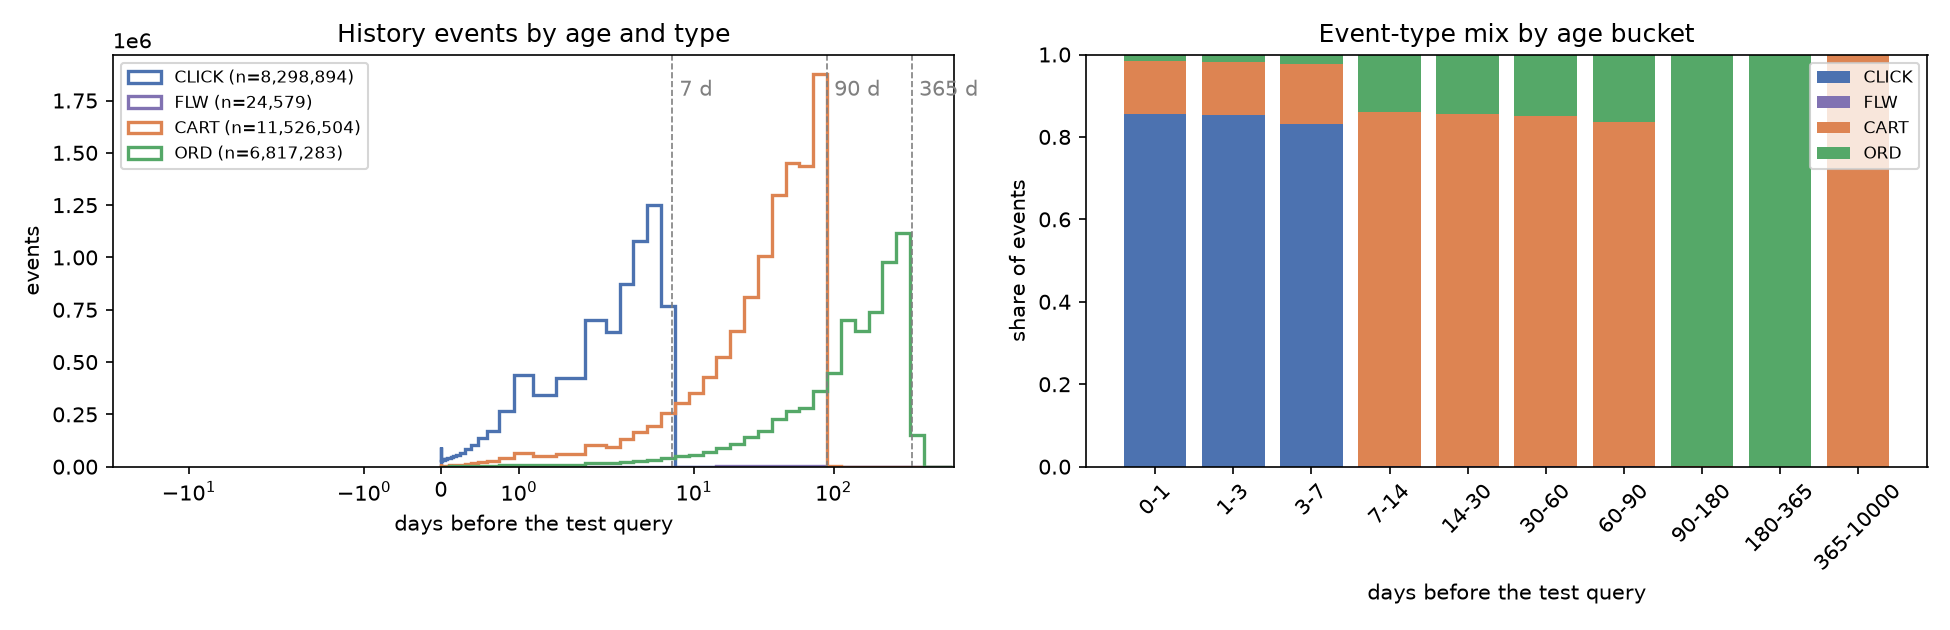

,type,n,p50,p99,p999,max,type_name
0,1,8298894,2.791979,6.489595,6.885313,13.145312,CLICK
1,2,24579,39.443935,87.698425,89.359146,89.986595,FLW
2,3,11526504,38.373692,88.306122,89.458969,635.289856,CART
3,4,6817283,154.080200,359.576172,363.995087,364.986450,ORD


In [5]:
run.figure("history_timeline.png")
import pandas as pd
pd.DataFrame(run.json("eda.json")["retention"])

### Funnel by elapsed days (interim feedback)

Clicks per cart and carts per order in each age bucket. Shaded bands are typical e-commerce ranges (clicks:carts 5–10,
carts:orders 3–5). Read where the ratios fall off a cliff: that is where a type's log ends.

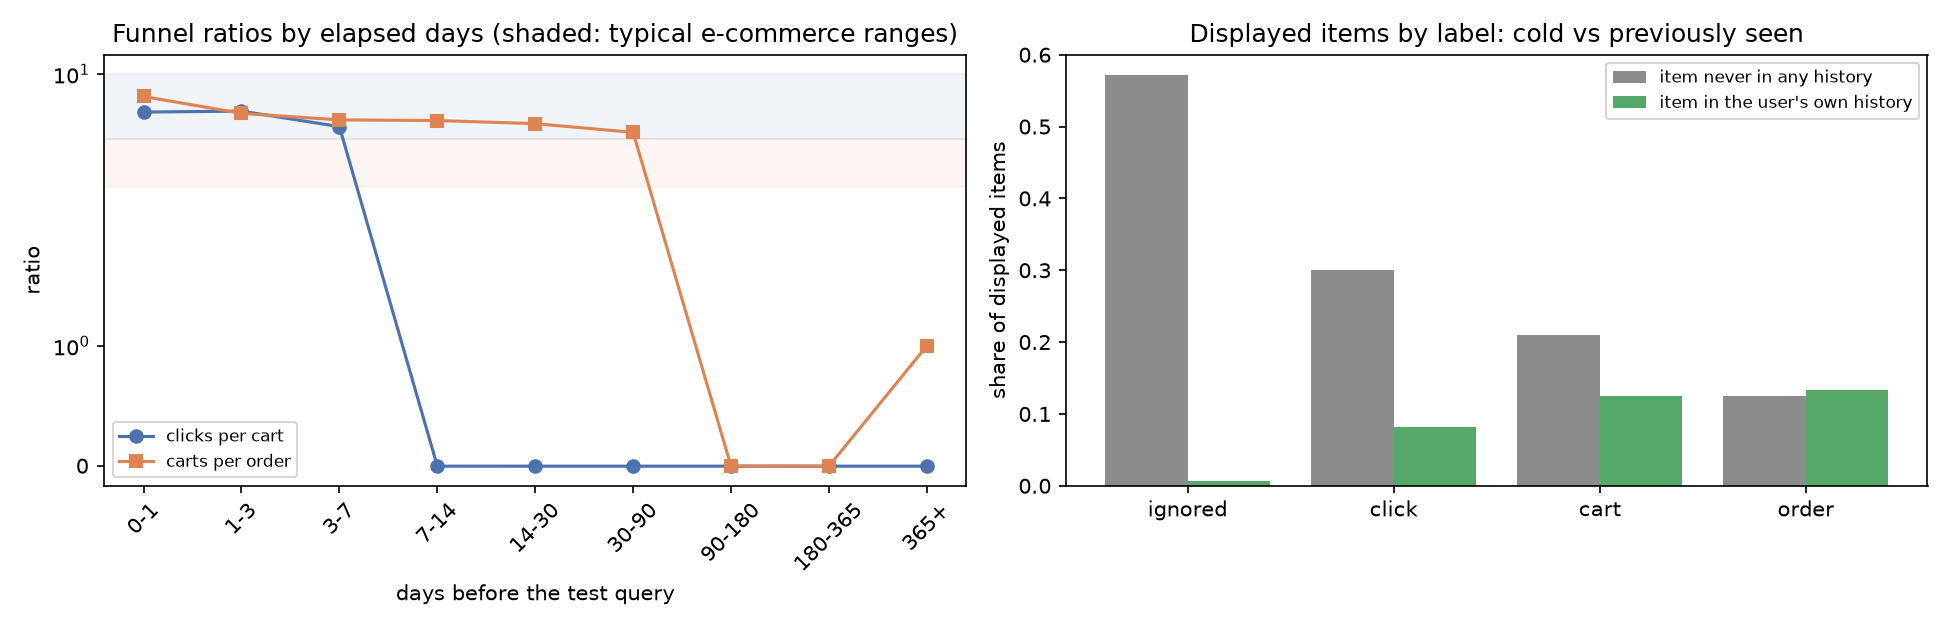

,bucket,events,click,follow,cart,order,users,clicks_per_cart,carts_per_order,cum_share_of_events
0,0-1,2242574,1918289,616,287228,36441,111530,6.6786,7.8820,0.0841
1,1-3,2967830,2534453,629,375715,57033,98224,6.7457,6.5877,0.1954
2,3-7,4629013,3846045,1406,672214,109348,115936,5.7215,6.1475,0.3690
3,7-14,1245775,107,2210,1068418,175040,105236,0.0001,6.1039,0.4157
4,14-30,2615709,0,5209,2232532,377968,129411,0.0000,5.9067,0.5138
5,30-90,8183797,0,14509,6889193,1280095,150477,0.0000,5.3818,0.8207
6,90-180,1825329,0,0,1203,1824126,120439,0.0000,0.0007,0.8891
7,180-365,2957232,0,0,0,2957232,116051,0.0000,0.0000,1.0000
8,365+,1,0,0,1,0,1,0.0000,1.0000,1.0000


In [6]:
run.figure("funnel_by_age.png")
run.table("eda_funnel_by_age.csv", highlight=())

In [7]:
eda = run.json("eda.json")
print("History that can never have a recorded click:")
eda["missing_clicks"]

History that can never have a recorded click:


{'carts_older_than_click_window': 0.8841663526078679,
 'orders_older_than_click_window': 0.9702488513385757,
 'events_older_than_click_window': 0.6310300720808962,
 'clicks_older_than_click_window': 1.2893284334032945e-05,
 'users_with_orders_but_no_clicks': 0.1463030184489533,
 'overall_clicks_per_cart': 0.7199836134182576,
 'overall_carts_per_order': 1.69077680947087}

In [8]:
print("Naive click ratio vs share of recent history (correlation):")
eda["recency_confound"]

Naive click ratio vs share of recent history (correlation):


{'corr_click_ratio_vs_recent_share': 0.9531554961566894,
 'users_without_clicks': 0.16213448694421595,
 'n_users': 173831}

### The supervised signal: displayed slates and graded labels

Labels: 0 ignored, 1 click, 2 cart, 3 order. How many positives a slate has, what the deepest engagement is, and how
many displayed items are *cold* (never in anyone's history) — the reason the item tower is built from content rather
than item-id embeddings.

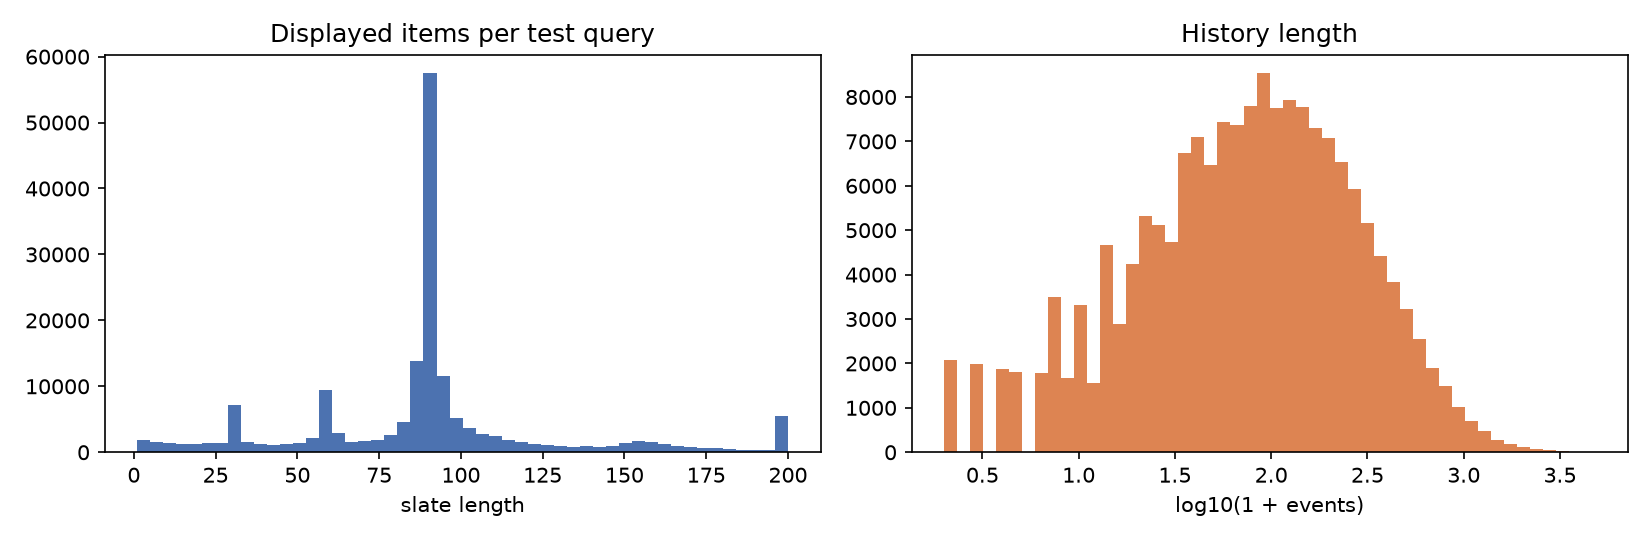

{'positives_per_slate': {'0': 2103,
  '1': 103192,
  '2': 36064,
  '3-5': 26297,
  '6+': 6175},
 'max_label_share': {'0': 0.012097957211314438,
  '1': 0.5654342436044204,
  '2': 0.30565319189327567,
  '3': 0.11681460729098953},
 'mean_positive_rate_in_slate': 0.030638238480276647,
 'by_label': [{'label': 0,
   'n': 15189116,
   'never_in_any_history': 0.5717019344641255,
   'in_users_own_history': 0.006004233557765969},
  {'label': 1,
   'n': 224487,
   'never_in_any_history': 0.30091274773149446,
   'in_users_own_history': 0.08163947132796108},
  {'label': 2,
   'n': 75573,
   'never_in_any_history': 0.21040583277096317,
   'in_users_own_history': 0.12456829820173872},
  {'label': 3,
   'n': 20836,
   'never_in_any_history': 0.12526396621232483,
   'in_users_own_history': 0.13308696486849683}]}

In [9]:
run.figure("slates_and_history.png")
eda["slates"]

In [10]:
print("Item popularity as a ranking signal (pooled AUC), counted inside each type window vs all history:")
eda["popularity_auc"]

Item popularity as a ranking signal (pooled AUC), counted inside each type window vs all history:


{'all_events': 0.7000084278821874,
 'click_7': 0.687174984160263,
 'cart_90': 0.6830646133614267,
 'order_365': 0.6446947759797665}